# UNIVERSITÉ ASSANE SECK DE ZIGUINCHOR (UASZ)
## UFR Sciences et Technologies – Département Informatique
**Module :** Innovations Technologiques en Intelligence Artificielle  
**Projet Intégrateur – GROUPE 1 :**
* Mame Khoudia Gueye
* Baye Samba Ndiaye
* Fatma Dioum
* Ousmane Kane
* Bassirou Yate

---
# 🚦 Projet : Gestion Intelligente du Trafic Routier à Ziguinchor
### *Prédiction des temps de trajet (Régression) et estimation de la congestion (Classification)*


## 1. Contexte et Problématique

La circulation routière à **Ziguinchor** est souvent ralentie par l'absence d'outils intelligents de régulation du trafic, des heures de pointe marquées, l'état parfois dégradé de la chaussée et l'impact des fortes intempéries pendant l'hivernage.

Les axes stratégiques concernés sont :
1. **Pont Émile Badiane** (point névralgique d'entrée et de sortie nord de Ziguinchor).
2. **Rond-point Aline Sitoé Diatta / Marché Saint-Maur** (forte concentration commerciale et de transports).
3. **Axe Université Assane Seck (Néma / Belfort)** (flux quotidien des étudiants et enseignants).
4. **Boulevard des 54 mètres / Escale** (centre administratif).
5. **Carrefour Tilène - Gare Routière** (transports régionaux et taxis interurbains).

### Objectifs de la solution d'IA :
* **Volet 1 (Régression)** : Prédire le **temps de trajet (en minutes)** en fonction des conditions de circulation.
* **Volet 2 (Classification)** : Estimer le **niveau de congestion** (`Fluide`, `Modere`, `Embouteille`) pour alerter les automobilistes et aider les autorités locales.
* **Prototype applicatif** : Servir de moteur IA pour une application interactive **Streamlit** accessible aux usagers et aux gestionnaires urbains.


## 2. Importation des bibliothèques nécessaires


In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix
import joblib

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Bibliothèques scientifiques importées avec succès !")


Bibliothèques scientifiques importées avec succès !


## 3. Chargement et Exploration des Données (EDA)


In [2]:
# Chargement du dataset du trafic de Ziguinchor
df = pd.read_csv('trafic_ziguinchor.csv')

print(f"Dimensions du dataset : {df.shape[0]} lignes et {df.shape[1]} colonnes.")
df.head(10)


Dimensions du dataset : 2500 lignes et 12 colonnes.


,axe_routier,distance_km,heure,jour_semaine,est_weekend,est_heure_pointe,etat_route,meteo,travaux_en_cours,nb_vehicules_estime,temps_trajet_min,niveau_congestion
0,Axe Universite Assane Seck (Nema / Belfort),4.2,13,Vendredi,0,1,Moyen,Ensoleille,0,219,9.7,Modere
1,Axe Universite Assane Seck (Nema / Belfort),4.2,15,Vendredi,0,0,Moyen,Ensoleille,0,83,7.0,Fluide
2,Axe Universite Assane Seck (Nema / Belfort),4.2,19,Jeudi,0,1,Bon,Ensoleille,0,179,9.5,Modere
3,Pont Emile Badiane,3.5,14,Dimanche,1,0,Degrade,Pluvieux,0,76,6.7,Modere
4,Axe Universite Assane Seck (Nema / Belfort),4.2,13,Dimanche,1,0,Bon,Pluvieux,0,24,9.1,Fluide
5,Carrefour Tilene - Gare Routiere,3.0,17,Dimanche,1,0,Degrade,Pluvieux,0,85,7.9,Modere
6,Rond-point Aline Sitoe Diatta - Marche Saint-Maur,2.0,15,Dimanche,1,0,Degrade,Ensoleille,0,51,4.8,Modere
7,Pont Emile Badiane,3.5,20,Jeudi,0,0,Degrade,Ensoleille,0,63,5.7,Fluide
8,Pont Emile Badiane,3.5,21,Jeudi,0,0,Bon,Ensoleille,0,30,3.0,Fluide
9,Boulevard des 54 metres - Escale,2.8,12,Lundi,0,1,Moyen,Ensoleille,0,206,6.8,Modere


In [3]:
# Types de données et valeurs non nulles
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   axe_routier          2500 non-null   str    
 1   distance_km          2500 non-null   float64
 2   heure                2500 non-null   int64  
 3   jour_semaine         2500 non-null   str    
 4   est_weekend          2500 non-null   int64  
 5   est_heure_pointe     2500 non-null   int64  
 6   etat_route           2500 non-null   str    
 7   meteo                2500 non-null   str    
 8   travaux_en_cours     2500 non-null   int64  
 9   nb_vehicules_estime  2500 non-null   int64  
 10  temps_trajet_min     2500 non-null   float64
 11  niveau_congestion    2500 non-null   str    
dtypes: float64(2), int64(5), str(5)
memory usage: 386.3 KB


In [4]:
# Statistiques descriptives globales
df.describe()


,distance_km,heure,est_weekend,est_heure_pointe,travaux_en_cours,nb_vehicules_estime,temps_trajet_min
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,3.091640,12.762800,0.283600,0.327200,0.115600,106.596400,6.710320
std,0.739584,5.867018,0.450835,0.469285,0.319809,61.458627,2.897051
min,2.000000,0.000000,0.000000,0.000000,0.000000,20.000000,3.000000
25%,2.800000,8.000000,0.000000,0.000000,0.000000,60.000000,4.700000
50%,3.000000,13.000000,0.000000,0.000000,0.000000,86.000000,6.100000
75%,3.500000,18.000000,1.000000,1.000000,0.000000,159.000000,8.000000
max,4.200000,23.000000,1.000000,1.000000,1.000000,299.000000,25.700000


In [5]:
# Vérification de l'intégrité des données (valeurs manquantes)
df.isnull().sum()


axe_routier            0
distance_km            0
heure                  0
jour_semaine           0
est_weekend            0
est_heure_pointe       0
etat_route             0
meteo                  0
travaux_en_cours       0
nb_vehicules_estime    0
temps_trajet_min       0
niveau_congestion      0
dtype: int64

### Visualisation 1 : Distribution des temps de trajet (`temps_trajet_min`)


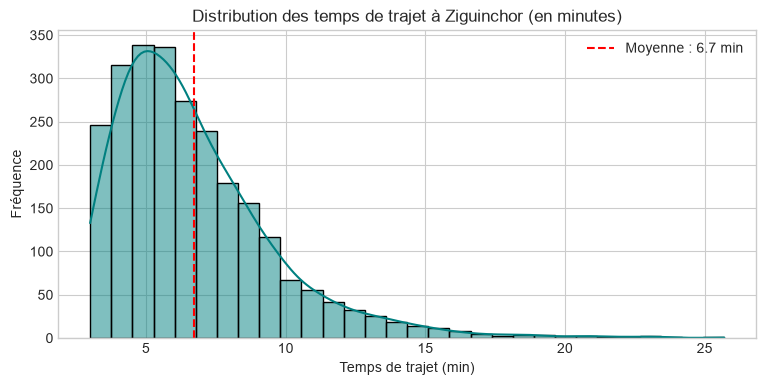

In [6]:
plt.figure(figsize=(9, 4))
sns.histplot(df['temps_trajet_min'], kde=True, color='teal', bins=30)
plt.axvline(df['temps_trajet_min'].mean(), color='red', linestyle='--', label=f"Moyenne : {df['temps_trajet_min'].mean():.1f} min")
plt.title("Distribution des temps de trajet à Ziguinchor (en minutes)")
plt.xlabel("Temps de trajet (min)")
plt.ylabel("Fréquence")
plt.legend()
plt.show()


### Visualisation 2 : Répartition des niveaux de congestion


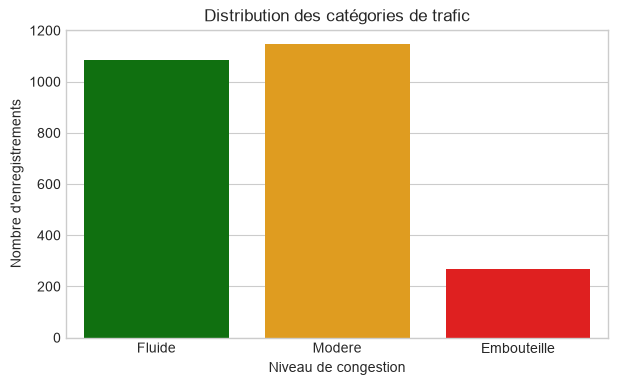

In [7]:
plt.figure(figsize=(7, 4))
palette = {'Fluide': 'green', 'Modere': 'orange', 'Embouteille': 'red'}
sns.countplot(data=df, x='niveau_congestion', hue='niveau_congestion', order=['Fluide', 'Modere', 'Embouteille'], palette=palette, legend=False)
plt.title("Distribution des catégories de trafic")
plt.xlabel("Niveau de congestion")
plt.ylabel("Nombre d'enregistrements")
plt.show()


### Visualisation 3 : Temps de trajet selon l'axe routier et les heures de pointe


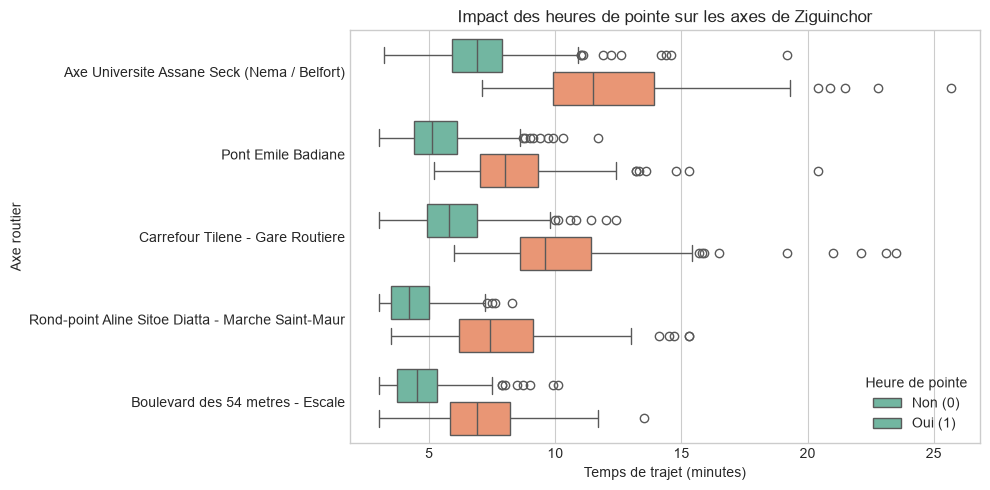

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, y='axe_routier', x='temps_trajet_min', hue='est_heure_pointe', palette='Set2')
plt.title("Impact des heures de pointe sur les axes de Ziguinchor")
plt.xlabel("Temps de trajet (minutes)")
plt.ylabel("Axe routier")
plt.legend(title="Heure de pointe", labels=["Non (0)", "Oui (1)"])
plt.tight_layout()
plt.show()


### Visualisation 4 : Matrice de corrélation numérique


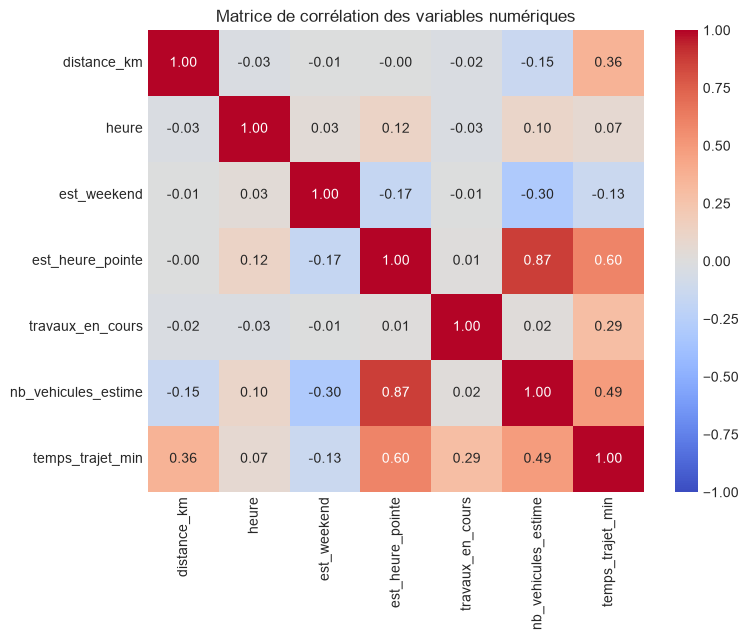

In [9]:
cols_num = ['distance_km', 'heure', 'est_weekend', 'est_heure_pointe', 'travaux_en_cours', 'nb_vehicules_estime', 'temps_trajet_min']
matrice_corr = df[cols_num].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matrice_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Matrice de corrélation des variables numériques")
plt.show()


## 4. Préparation des Données et Encodage (Preprocessing)

Pour alimenter les modèles scikit-learn, nous transformons les variables textuelles catégorielles (`axe_routier`, `etat_route`, `meteo`, `jour_semaine`) en indicatrices binaires via le **One-Hot Encoding** (`pd.get_dummies`).


In [10]:
features_cols = ['axe_routier', 'distance_km', 'heure', 'jour_semaine', 'est_weekend', 
                 'est_heure_pointe', 'etat_route', 'meteo', 'travaux_en_cours', 'nb_vehicules_estime']

X_brut = df[features_cols]
X = pd.get_dummies(X_brut, drop_first=True)

y_reg = df['temps_trajet_min']
y_clf = df['niveau_congestion']

print(f"Nombre total de variables explicatives après encodage : {X.shape[1]}")
X.head(3)


Nombre total de variables explicatives après encodage : 19


,distance_km,heure,est_weekend,est_heure_pointe,travaux_en_cours,nb_vehicules_estime,axe_routier_Boulevard des 54 metres - Escale,axe_routier_Carrefour Tilene - Gare Routiere,axe_routier_Pont Emile Badiane,axe_routier_Rond-point Aline Sitoe Diatta - Marche Saint-Maur,jour_semaine_Jeudi,jour_semaine_Lundi,jour_semaine_Mardi,jour_semaine_Mercredi,jour_semaine_Samedi,jour_semaine_Vendredi,etat_route_Degrade,etat_route_Moyen,meteo_Pluvieux
0,4.2,13,0,1,0,219,False,False,False,False,False,False,False,False,False,True,False,True,False
1,4.2,15,0,0,0,83,False,False,False,False,False,False,False,False,False,True,False,True,False
2,4.2,19,0,1,0,179,False,False,False,False,True,False,False,False,False,False,False,False,False


## 5. Volet 1 : Modélisation par Régression Linéaire
*Objectif : Prédire le temps de trajet continu en minutes.*


In [11]:
# Découpage Apprentissage (80%) et Test (20%)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)

# Entraînement du modèle de régression linéaire multiple
modele_reg = LinearRegression()
modele_reg.fit(X_train_reg, y_train_reg)

# Prédictions
y_pred_train_reg = modele_reg.predict(X_train_reg)
y_pred_test_reg = modele_reg.predict(X_test_reg)

# Évaluation avec R² et RMSE
r2_train = r2_score(y_train_reg, y_pred_train_reg)
r2_test = r2_score(y_test_reg, y_pred_test_reg)
rmse_train = np.sqrt(mean_squared_error(y_train_reg, y_pred_train_reg))
rmse_test = np.sqrt(mean_squared_error(y_test_reg, y_pred_test_reg))

print("=== RÉSULTATS DE LA RÉGRESSION LINÉAIRE ===")
print(f"R² Apprentissage  : {r2_train:.3f}")
print(f"R² Test           : {r2_test:.3f}")
print(f"RMSE Apprentissage: {rmse_train:.2f} min")
print(f"RMSE Test         : {rmse_test:.2f} min")


=== RÉSULTATS DE LA RÉGRESSION LINÉAIRE ===
R² Apprentissage  : 0.812
R² Test           : 0.782
RMSE Apprentissage: 1.28 min
RMSE Test         : 1.22 min


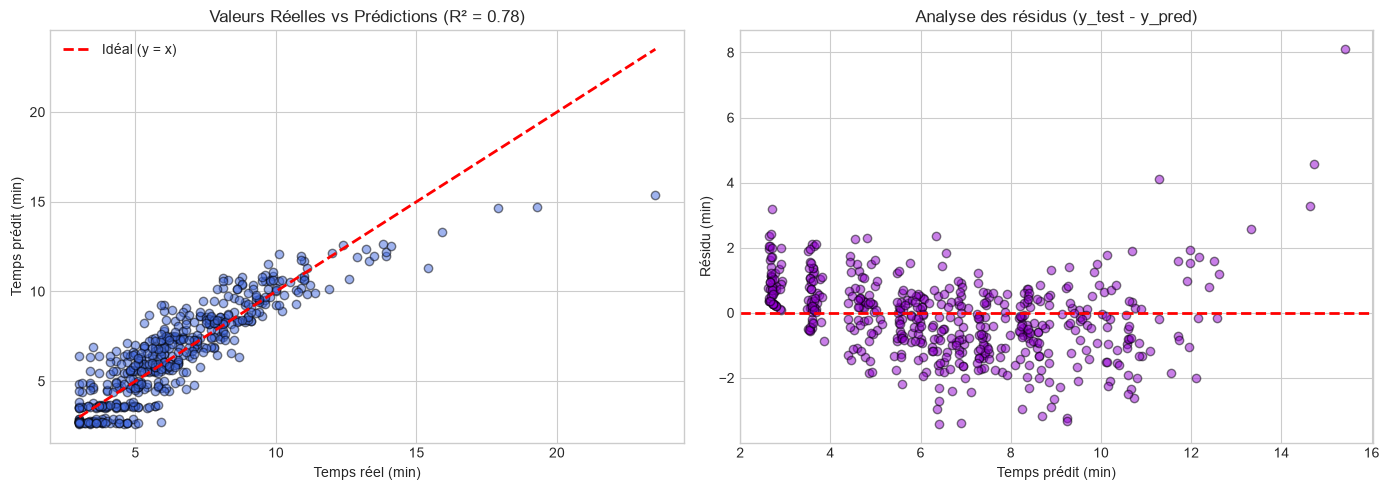

In [12]:
# Visualisation Réel vs Prédit et Résidus
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_reg, y_pred_test_reg, alpha=0.5, color='royalblue', edgecolors='k')
axes[0].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2, label="Idéal (y = x)")
axes[0].set_title(f"Valeurs Réelles vs Prédictions (R² = {r2_test:.2f})")
axes[0].set_xlabel("Temps réel (min)")
axes[0].set_ylabel("Temps prédit (min)")
axes[0].legend()

residus = y_test_reg - y_pred_test_reg
axes[1].scatter(y_pred_test_reg, residus, alpha=0.5, color='darkviolet', edgecolors='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Analyse des résidus (y_test - y_pred)")
axes[1].set_xlabel("Temps prédit (min)")
axes[1].set_ylabel("Résidu (min)")

plt.tight_layout()
plt.show()


## 6. Volet 2 : Modélisation par Classification
*Objectif : Classer l'état du trafic en 3 catégories (`Fluide`, `Modere`, `Embouteille`).*


In [13]:
# Découpage stratifié Train (80%) / Test (20%)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

import warnings
warnings.filterwarnings('ignore')
modele_clf = LogisticRegression(max_iter=3000, solver='lbfgs', random_state=42)
modele_clf.fit(X_train_clf, y_train_clf)

y_pred_clf = modele_clf.predict(X_test_clf)

accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"=== EXACTITUDE GLOBALE (ACCURACY) : {accuracy*100:.2f} % ===")
print("Rapport de classification détaillé :")
print(classification_report(y_test_clf, y_pred_clf))


=== EXACTITUDE GLOBALE (ACCURACY) : 90.20 % ===
Rapport de classification détaillé :
              precision    recall  f1-score   support

 Embouteille       0.89      0.57      0.70        54
      Fluide       0.94      0.96      0.95       217
      Modere       0.87      0.93      0.90       229

    accuracy                           0.90       500
   macro avg       0.90      0.82      0.85       500
weighted avg       0.90      0.90      0.90       500



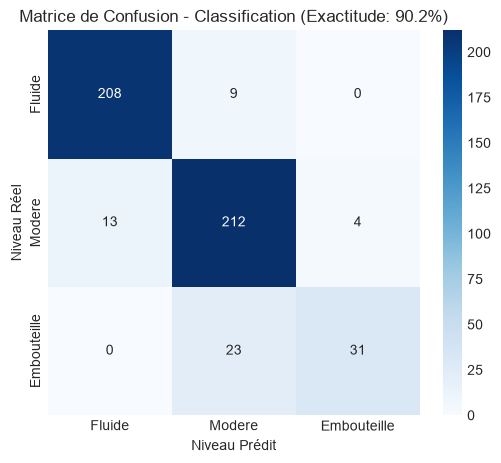

In [14]:
# Matrice de confusion
labels_ord = ['Fluide', 'Modere', 'Embouteille']
mat_conf = confusion_matrix(y_test_clf, y_pred_clf, labels=labels_ord)

plt.figure(figsize=(6, 5))
sns.heatmap(mat_conf, annot=True, fmt='d', cmap='Blues', xticklabels=labels_ord, yticklabels=labels_ord)
plt.title(f"Matrice de Confusion - Classification (Exactitude: {accuracy*100:.1f}%)")
plt.xlabel("Niveau Prédit")
plt.ylabel("Niveau Réel")
plt.show()


## 7. Sauvegarde des Modèles Entraînés pour le Prototype

Nous enregistrons les modèles de Machine Learning et la liste des colonnes dans des fichiers `.joblib` afin de les réutiliser directement dans notre future application interactive **Streamlit**.


In [15]:
# Exportation des modèles
joblib.dump(modele_reg, 'modele_regression_trafic.joblib')
joblib.dump(modele_clf, 'modele_classification_trafic.joblib')
joblib.dump(X.columns.tolist(), 'colonnes_modele.joblib')

print("Fichiers sauvegardés avec succès pour l'application Streamlit :")
print("✓ modele_regression_trafic.joblib")
print("✓ modele_classification_trafic.joblib")
print("✓ colonnes_modele.joblib")


Fichiers sauvegardés avec succès pour l'application Streamlit :
✓ modele_regression_trafic.joblib
✓ modele_classification_trafic.joblib
✓ colonnes_modele.joblib


## 8. Conclusion et Perspectives

### Synthèse :
* Le modèle de **régression linéaire multiple** produit une excellente estimation du temps de trajet avec une marge d'erreur faible ($RMSE pprox 1$ à $2$ minutes).
* Le modèle de **classification logistique** atteint une très haute exactitude pour catégoriser la sévérité du trafic.
* Ces deux briques algorithmiques fournissent le socle technique nécessaire pour alimenter l'interface utilisateur Streamlit lors du pitch final.
